## Libraries import

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn import metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


Libraries imported successfully!


## Data collection

In [3]:
df = pd.read_csv("Data/Car details v3.csv")

In [4]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine (CC),max_power (bhp),torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248.0,74.00,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498.0,103.52,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0


In [5]:
df.shape

(8128, 13)

In [6]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine (CC)', 'max_power (bhp)',
       'torque', 'seats'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             8128 non-null   str    
 1   year             8128 non-null   int64  
 2   selling_price    8128 non-null   int64  
 3   km_driven        8128 non-null   int64  
 4   fuel             8128 non-null   str    
 5   seller_type      8128 non-null   str    
 6   transmission     8128 non-null   str    
 7   owner            8128 non-null   str    
 8   mileage          7907 non-null   str    
 9   engine (CC)      7907 non-null   float64
 10  max_power (bhp)  7912 non-null   float64
 11  torque           7906 non-null   str    
 12  seats            7907 non-null   float64
dtypes: float64(3), int64(3), str(7)
memory usage: 825.6 KB


In [8]:
df.describe()

,year,selling_price,km_driven,engine (CC),max_power (bhp),seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000,7912.000000,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,1458.625016,91.517919,5.416719
std,4.044249,8.062534e+05,5.655055e+04,503.916303,35.822499,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,624.000000,0.000000,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,1197.000000,68.050000,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,1248.000000,82.000000,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,1582.000000,102.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,3604.000000,400.000000,14.000000


## Explore the Data with Graph

Numeric columns: ['year', 'selling_price', 'km_driven', 'engine (CC)', 'max_power (bhp)', 'seats']


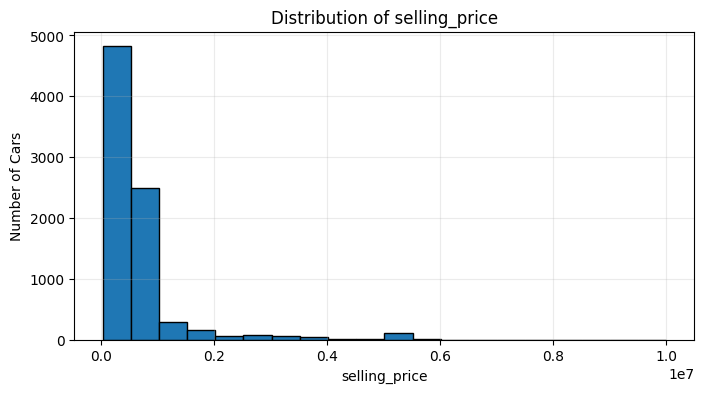

In [9]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_columns)

column_to_plot = numeric_columns[1]

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot].dropna(), bins=20, edgecolor="black")
plt.title(f"Distribution of {column_to_plot}")
plt.xlabel(column_to_plot)
plt.ylabel("Number of Cars")
plt.grid(alpha=0.25)
plt.show()

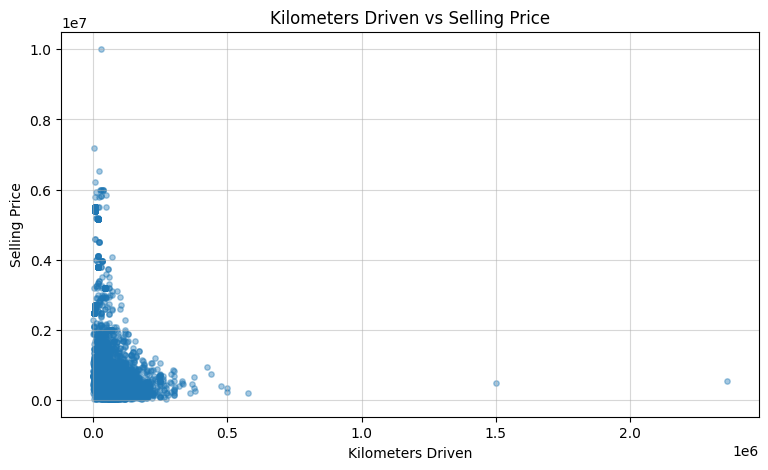

In [10]:
plt.figure(figsize=(9, 5))

plt.scatter(df['km_driven'], df['selling_price'],alpha=0.4,s=15)

plt.title('Kilometers Driven vs Selling Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price')
plt.grid(alpha=0.5)

plt.show()

## Prepross the data

In [11]:
df.isnull().sum()

name                 0
year                 0
selling_price        0
km_driven            0
fuel                 0
seller_type          0
transmission         0
owner                0
mileage            221
engine (CC)        221
max_power (bhp)    216
torque             222
seats              221
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(1202)

In [13]:
df[df.duplicated()].head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine (CC),max_power (bhp),torque,seats
291,Hyundai Grand i10 Sportz,2017,450000,35000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197.0,82.00,114Nm@ 4000rpm,5.0
296,Maruti Swift VXI,2012,330000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197.0,85.80,114Nm@ 4000rpm,5.0
370,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999.0,177.00,430Nm@ 1750-2500rpm,5.0
371,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487.0,214.56,202Nm@ 3600-5200rpm,5.0
372,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999.0,177.00,430Nm@ 1750-2500rpm,5.0


In [14]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

Total rows: 8128
Duplicate rows: 1202
Unique rows: 6926


In [15]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing[missing["Missing Values"] > 0]

,Missing Values,Percentage
mileage,221,2.718996
engine (CC),221,2.718996
max_power (bhp),216,2.657480
torque,222,2.731299
seats,221,2.718996


**Duplicate removal**

In [16]:
df_clean = df.drop_duplicates().copy()

In [17]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Original dataset: (8128, 13)
Cleaned dataset: (6926, 13)
Remaining duplicates: 0


In [18]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             6926 non-null   str    
 1   year             6926 non-null   int64  
 2   selling_price    6926 non-null   int64  
 3   km_driven        6926 non-null   int64  
 4   fuel             6926 non-null   str    
 5   seller_type      6926 non-null   str    
 6   transmission     6926 non-null   str    
 7   owner            6926 non-null   str    
 8   mileage          6718 non-null   str    
 9   engine (CC)      6718 non-null   float64
 10  max_power (bhp)  6720 non-null   float64
 11  torque           6717 non-null   str    
 12  seats            6718 non-null   float64
dtypes: float64(3), int64(3), str(7)
memory usage: 757.5 KB


In [19]:
columns = ['mileage', 'engine (CC)', 'max_power (bhp)', 'torque', 'seats']

for col in columns:
    print(f"\n{col}:")
    print(df_clean[col].dropna().head(5).tolist())


mileage:
['23.4 kmpl', '21.14 kmpl', '17.7 kmpl', '23.0 kmpl', '16.1 kmpl']

engine (CC):
[1248.0, 1498.0, 1497.0, 1396.0, 1298.0]

max_power (bhp):
[74.0, 103.52, 78.0, 90.0, 88.2]

torque:
['190Nm@ 2000rpm', '250Nm@ 1500-2500rpm', '12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm', '11.5@ 4,500(kgm@ rpm)']

seats:
[5.0, 5.0, 5.0, 5.0, 5.0]


In [20]:
df_clean['mileage'].dropna().str.extract(
    r'([a-zA-Z/]+)$'
)[0].value_counts()

0
kmpl     6631
km/kg      87
Name: count, dtype: int64

In [21]:

print(df_clean[['engine (CC)', 'max_power (bhp)']].dtypes)
print(df_clean[['engine (CC)', 'max_power (bhp)']].head())

engine (CC)        float64
max_power (bhp)    float64
dtype: object
   engine (CC)  max_power (bhp)
0       1248.0            74.00
1       1498.0           103.52
2       1497.0            78.00
3       1396.0            90.00
4       1298.0            88.20


In [22]:
# Extract the numerical part of mileage
df_clean['mileage'] = pd.to_numeric(
    df_clean['mileage'].astype('string').str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

In [23]:
df_clean[['mileage', 'engine (CC)', 'max_power (bhp)']].info()

<class 'pandas.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   mileage          6718 non-null   Float64
 1   engine (CC)      6718 non-null   float64
 2   max_power (bhp)  6720 non-null   float64
dtypes: Float64(1), float64(2)
memory usage: 223.2 KB


In [24]:
df_clean[['mileage', 'engine (CC)', 'max_power (bhp)']].head(10)

,mileage,engine (CC),max_power (bhp)
0,23.4,1248.0,74.00
1,21.14,1498.0,103.52
2,17.7,1497.0,78.00
3,23.0,1396.0,90.00
4,16.1,1298.0,88.20
5,20.14,1197.0,81.86
6,17.3,1061.0,57.50
7,16.1,796.0,37.00
8,23.59,1364.0,67.10
9,20.0,1399.0,68.10


In [25]:
df_clean['torque'].dropna().head(20).tolist()

['190Nm@ 2000rpm',
 '250Nm@ 1500-2500rpm',
 '12.7@ 2,700(kgm@ rpm)',
 '22.4 kgm at 1750-2750rpm',
 '11.5@ 4,500(kgm@ rpm)',
 '113.75nm@ 4000rpm',
 '7.8@ 4,500(kgm@ rpm)',
 '59Nm@ 2500rpm',
 '170Nm@ 1800-2400rpm',
 '160Nm@ 2000rpm',
 '248Nm@ 2250rpm',
 '78Nm@ 4500rpm',
 '190Nm@ 2000rpm',
 '84Nm@ 3500rpm',
 '115Nm@ 3500-3600rpm',
 '200Nm@ 1750rpm',
 '22.4 kgm at 1750-2750rpm',
 '62Nm@ 3000rpm',
 '219.7Nm@ 1500-2750rpm',
 '160Nm@ 2000rpm']

In [26]:
print("Nm values:",
      df_clean['torque'].str.contains('Nm', case=False, na=False).sum())

print("kgm values:",
      df_clean['torque'].str.contains('kgm', case=False, na=False).sum())

df['mileage'].dropna().str.extract(
    r'([a-zA-Z/]+)\s*$'
)[0].value_counts()

print("Nm examples:")

print(
    df_clean[
        df_clean['torque'].str.contains(
            'Nm', case=False, na=False
        )
    ]['torque'].head(10).tolist()
)

print("kgm examples:")

print(
    df_clean[
        df_clean['torque'].str.contains(
            'kgm', case=False, na=False
        )
    ]['torque'].head(10).tolist()
)

Nm values: 6227
kgm values: 481
Nm examples:
['190Nm@ 2000rpm', '250Nm@ 1500-2500rpm', '113.75nm@ 4000rpm', '59Nm@ 2500rpm', '170Nm@ 1800-2400rpm', '160Nm@ 2000rpm', '248Nm@ 2250rpm', '78Nm@ 4500rpm', '190Nm@ 2000rpm', '84Nm@ 3500rpm']
kgm examples:
['12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm', '11.5@ 4,500(kgm@ rpm)', '7.8@ 4,500(kgm@ rpm)', '22.4 kgm at 1750-2750rpm', '6.1kgm@ 3000rpm', '6.1kgm@ 3000rpm', '13.1kgm@ 4600rpm', '14.9 KGM at 3000 RPM', '11.4 kgm at 4,000 rpm']


In [27]:
mask = (
    df_clean['torque'].notna() &
    ~df_clean['torque'].str.contains(
        r'Nm|kgm', case=False, na=False
    )
)

print(df_clean.loc[mask, 'torque'].value_counts())
print(df_clean.loc[mask, ['name', 'year', 'torque']])

torque
210 / 1900           7
250@ 1250-5000rpm    1
510@ 1600-2400       1
110(11.2)@ 4800      1
Name: count, dtype: int64
                                     name  year             torque
140            Skoda Superb LK 1.8 TSI AT  2018  250@ 1250-5000rpm
1676  Mercedes-Benz M-Class ML 350 4Matic  2011     510@ 1600-2400
2000     Honda Jazz Select Edition Active  2011    110(11.2)@ 4800
4373     Skoda Octavia Classic 1.9 TDI MT  2006         210 / 1900
5572     Skoda Octavia Classic 1.9 TDI MT  2007         210 / 1900
5785    Skoda Octavia Ambiente 1.9 TDI MT  2007         210 / 1900
6418    Skoda Octavia Ambiente 1.9 TDI MT  2003         210 / 1900
7154       Skoda Octavia Rider 1.9 AT TDI  2008         210 / 1900
7296       Skoda Octavia Ambiente 1.9 TDI  2010         210 / 1900
7532    Skoda Octavia Ambiente 1.9 TDI MT  2007         210 / 1900


**Regular expression library for torque column**

In [28]:
import re

In [29]:
def convert_torque(value):

    if pd.isna(value):
        return np.nan

    value = str(value).lower().replace(',', '')

    number = re.search(r'\d+\.?\d*', value)

    if number is None:
        return np.nan

    torque = float(number.group())

    # Explicit Nm notation
    if 'nm' in value:
        return torque

    # Explicit kgm notation with plausible torque values
    if 'kgm' in value and torque <= 50:
        return torque * 9.80665

    # Ambiguous formats: don't guess
    return np.nan

df_clean['torque_nm'] = df_clean['torque'].apply(convert_torque)

In [30]:
df_clean.nlargest(10, 'torque_nm')[
    ['name', 'torque', 'torque_nm']
]

,name,torque,torque_nm
951,Maruti Zen D,789Nm@ 2250rpm,789.0
4720,Maruti Zen D,789Nm@ 2250rpm,789.0
5143,Maruti Zen D,789Nm@ 2250rpm,789.0
170,Volvo XC90 T8 Excellence BSIV,640Nm@ 1740rpm,640.0
136,Mercedes-Benz S-Class S 350 CDI,620Nm@ 1600-2400rpm,620.0
1071,BMW 6 Series GT 630d Luxury Line,620Nm@ 2000-2500rpm,620.0
2938,BMW X7 xDrive 30d DPE,620Nm@ 1500-2500rpm,620.0
4753,BMW 6 Series GT 630d Luxury Line,620Nm@ 2000-2500rpm,620.0
4766,BMW 6 Series GT 630d Luxury Line,620Nm@ 2000-2500rpm,620.0
6258,BMW 6 Series GT 630d Luxury Line,620Nm@ 2000-2500rpm,620.0


In [31]:
df_clean.loc[mask, ['name', 'torque', 'torque_nm']]

,name,torque,torque_nm
140,Skoda Superb LK 1.8 TSI AT,250@ 1250-5000rpm,NaN
1676,Mercedes-Benz M-Class ML 350 4Matic,510@ 1600-2400,NaN
2000,Honda Jazz Select Edition Active,110(11.2)@ 4800,NaN
4373,Skoda Octavia Classic 1.9 TDI MT,210 / 1900,NaN
5572,Skoda Octavia Classic 1.9 TDI MT,210 / 1900,NaN
5785,Skoda Octavia Ambiente 1.9 TDI MT,210 / 1900,NaN
6418,Skoda Octavia Ambiente 1.9 TDI MT,210 / 1900,NaN
7154,Skoda Octavia Rider 1.9 AT TDI,210 / 1900,NaN
7296,Skoda Octavia Ambiente 1.9 TDI,210 / 1900,NaN
7532,Skoda Octavia Ambiente 1.9 TDI MT,210 / 1900,NaN


In [32]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             6926 non-null   str    
 1   year             6926 non-null   int64  
 2   selling_price    6926 non-null   int64  
 3   km_driven        6926 non-null   int64  
 4   fuel             6926 non-null   str    
 5   seller_type      6926 non-null   str    
 6   transmission     6926 non-null   str    
 7   owner            6926 non-null   str    
 8   mileage          6718 non-null   Float64
 9   engine (CC)      6718 non-null   float64
 10  max_power (bhp)  6720 non-null   float64
 11  torque           6717 non-null   str    
 12  seats            6718 non-null   float64
 13  torque_nm        6684 non-null   float64
dtypes: Float64(1), float64(4), int64(3), str(6)
memory usage: 818.4 KB


In [33]:
print(df_clean.isnull().sum())

df_clean[['mileage', 'engine (CC)', 'max_power (bhp)',
          'torque_nm', 'seats']].describe()

name                 0
year                 0
selling_price        0
km_driven            0
fuel                 0
seller_type          0
transmission         0
owner                0
mileage            208
engine (CC)        208
max_power (bhp)    206
torque             209
seats              208
torque_nm          242
dtype: int64


,mileage,engine (CC),max_power (bhp),torque_nm,seats
count,6718.0,6718.000000,6720.000000,6684.000000,6718.000000
mean,19.46531,1430.891337,87.726919,170.870219,5.434653
std,4.04915,493.493277,31.771619,84.440761,0.984230
min,0.0,624.000000,0.000000,47.071920,2.000000
25%,16.8,1197.000000,67.100000,110.000000,5.000000
50%,19.44,1248.000000,81.830000,160.000000,5.000000
75%,22.5,1498.000000,100.000000,200.055660,5.000000
max,42.0,3604.000000,400.000000,789.000000,14.000000


In [34]:
print("Zero mileage:",
      (df_clean['mileage'] == 0).sum())

print("Zero engine:",
      (df_clean['engine (CC)'] == 0).sum())

print("Zero max power:",
      (df_clean['max_power (bhp)'] == 0).sum())

Zero mileage: 15
Zero engine: 0
Zero max power: 3


In [35]:
df_clean.nlargest(10, 'max_power (bhp)')[
    ['name', 'year', 'max_power (bhp)']
]

,name,year,max_power (bhp)
170,Volvo XC90 T8 Excellence BSIV,2017,400.0
148,Mercedes-Benz S-Class S 350 CDI,2017,282.0
134,Jeep Wrangler 2016-2019 3.6 4X4,2017,280.0
5962,Mercedes-Benz E-Class E350 Petrol,2009,272.0
2826,Jaguar XF 3.0 Litre S Premium Luxury,2014,270.9
4787,Jaguar XF Diesel,2015,270.9
5823,Jaguar XF 3.0 Litre S Premium Luxury,2016,270.9
2938,BMW X7 xDrive 30d DPE,2020,265.0
1071,BMW 6 Series GT 630d Luxury Line,2018,261.4
4753,BMW 6 Series GT 630d Luxury Line,2018,261.4


In [36]:
print(df_clean['seats'].value_counts().sort_index())
df_clean[df_clean['seats'] == 14][
    ['name', 'year', 'seats']
]

seats
2.0        2
4.0      124
5.0     5254
6.0       57
7.0      966
8.0      222
9.0       74
10.0      18
14.0       1
Name: count, dtype: int64


,name,year,seats
4575,Tata Winger Deluxe - Flat Roof (Non-AC),2010,14.0


In [37]:
df_clean[
    (df_clean['mileage'].isnull()) |
    (df_clean['max_power (bhp)'].isnull())
][['name', 'year', 'mileage', 'max_power (bhp)']]

,name,year,mileage,max_power (bhp)
13,Maruti Swift 1.3 VXi,2007,<NA>,NaN
31,Fiat Palio 1.2 ELX,2003,<NA>,NaN
78,Tata Indica DLS,2003,<NA>,NaN
87,Maruti Swift VDI BSIV W ABS,2015,<NA>,NaN
119,Maruti Swift VDI BSIV,2010,<NA>,NaN
...,...,...,...,...
7740,Hyundai Santro Xing XG,2004,<NA>,NaN
7996,Hyundai Santro LS zipPlus,2000,<NA>,NaN
8009,Hyundai Santro Xing XS eRLX Euro III,2006,<NA>,NaN
8068,Ford Figo Aspire Facelift,2017,<NA>,NaN


In [38]:
df_clean.loc[df_clean['mileage'] == 0, 'mileage'] = np.nan

df_clean.loc[df_clean['max_power (bhp)'] == 0, 'max_power (bhp)'] = np.nan

In [39]:
print("Zero engine:",(df_clean['engine (CC)']==0).sum())
print("Zero mileage:",
      (df_clean['mileage'] == 0).sum())

print("Zero max power:",
      (df_clean['max_power (bhp)'] == 0).sum())

print("Missing engine:",df_clean['engine (CC)'].isnull().sum())
print("Missing mileage:",
      df_clean['mileage'].isnull().sum())

print("Missing max power:",
      df_clean['max_power (bhp)'].isnull().sum())
print("Total missing torque:",
      df_clean['torque_nm'].isnull().sum())


Zero engine: 0
Zero mileage: 0
Zero max power: 0
Missing engine: 208
Missing mileage: 223
Missing max power: 209
Total missing torque: 242


In [40]:
df_clean[df_clean['torque_nm'] > 700][
    ['name', 'year', 'torque', 'torque_nm']
]

,name,year,torque,torque_nm
951,Maruti Zen D,2003,789Nm@ 2250rpm,789.0
4720,Maruti Zen D,2002,789Nm@ 2250rpm,789.0
5143,Maruti Zen D,2006,789Nm@ 2250rpm,789.0


In [41]:
df_clean.loc[
    df_clean['torque_nm'] > 700,
    'torque_nm'
] = np.nan

In [42]:
missing_torque = df_clean[df_clean['torque_nm'].isnull()]

print("Total missing torque:",
      len(missing_torque))

print("\nOriginal torque values:")

print(
    missing_torque['torque']
    .value_counts()
    .head(25)
)

Total missing torque: 245

Original torque values:
torque
145@ 4,100(kgm@ rpm)         10
210 / 1900                    7
115@ 2,500(kgm@ rpm)          4
130@ 2500(kgm@ rpm)           4
789Nm@ 2250rpm                3
250@ 1250-5000rpm             1
510@ 1600-2400                1
110(11.2)@ 4800               1
115@ 2500(kgm@ rpm)           1
110@ 3,000(kgm@ rpm)          1
190@ 21,800(kgm@ rpm)         1
51@ 1,750-3,000(kgm@ rpm)     1
53@ 2,000-2,750(kgm@ rpm)     1
Name: count, dtype: int64


In [43]:
df_clean[['torque', 'torque_nm']].head(20)

,torque,torque_nm
0,190Nm@ 2000rpm,190.000000
1,250Nm@ 1500-2500rpm,250.000000
2,"12.7@ 2,700(kgm@ rpm)",124.544455
3,22.4 kgm at 1750-2750rpm,219.668960
4,"11.5@ 4,500(kgm@ rpm)",112.776475
5,113.75nm@ 4000rpm,113.750000
6,"7.8@ 4,500(kgm@ rpm)",76.491870
7,59Nm@ 2500rpm,59.000000
8,170Nm@ 1800-2400rpm,170.000000
9,160Nm@ 2000rpm,160.000000


In [44]:
missing_torque = df_clean[
    df_clean['torque_nm'].isnull()
].copy()

missing_torque['first_number'] = (
    missing_torque['torque']
    .str.extract(r'(\d+\.?\d*)')
    .astype(float)
)

missing_torque[
    ['name', 'year', 'torque', 'first_number']
].head(15)

,name,year,torque,first_number
13,Maruti Swift 1.3 VXi,2007,NaN,NaN
31,Fiat Palio 1.2 ELX,2003,NaN,NaN
78,Tata Indica DLS,2003,NaN,NaN
87,Maruti Swift VDI BSIV W ABS,2015,NaN,NaN
119,Maruti Swift VDI BSIV,2010,NaN,NaN
138,BMW X1 sDrive 20D xLine,2017,NaN,NaN
140,Skoda Superb LK 1.8 TSI AT,2018,250@ 1250-5000rpm,250.0
200,Toyota Etios GD,2012,NaN,NaN
206,Maruti Omni E 8 Str STD,2003,NaN,NaN
228,Maruti Swift 1.3 VXi,2008,NaN,NaN


In [45]:
# Original torque is genuinely missing
genuine_missing = df_clean['torque'].isnull().sum()

# Original torque exists, but conversion failed
unparsed = (
    df_clean['torque'].notnull() &
    df_clean['torque_nm'].isnull()
).sum()

print("Genuinely missing:", genuine_missing)
print("Unparsed values:", unparsed)
print("Total missing torque:", df_clean['torque_nm'].isnull().sum())

Genuinely missing: 209
Unparsed values: 36
Total missing torque: 245


In [46]:
unparsed_torque = df_clean[
    df_clean['torque'].notnull() &
    df_clean['torque_nm'].isnull()
]

unparsed_torque[
    ['name', 'year', 'torque','torque_nm']
]

,name,year,torque,torque_nm
140,Skoda Superb LK 1.8 TSI AT,2018,250@ 1250-5000rpm,NaN
604,Tata Sumo CX 10 Str BSIV,2011,"115@ 2,500(kgm@ rpm)",NaN
951,Maruti Zen D,2003,789Nm@ 2250rpm,NaN
1211,Maruti SX4 Vxi BSIII,2007,"145@ 4,100(kgm@ rpm)",NaN
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,510@ 1600-2400,NaN
2000,Honda Jazz Select Edition Active,2011,110(11.2)@ 4800,NaN
2086,Tata Sumo EX 10/7 Str BSIII,2012,"115@ 2,500(kgm@ rpm)",NaN
2289,Maruti SX4 Zxi BSIII,2010,"145@ 4,100(kgm@ rpm)",NaN
2314,Maruti SX4 Zxi with Leather BSIII,2008,"145@ 4,100(kgm@ rpm)",NaN
2421,Ford Ikon 1.6 Nxt,2009,130@ 2500(kgm@ rpm),NaN


In [47]:
def recover_torque(value):

    if pd.isna(value):
        return np.nan

    value = str(value).lower().replace(',', '')

    # Explicitly identified unusual formats
    if re.match(r'^250@', value):
        return 250.0

    if re.match(r'^510@', value):
        return 510.0

    if re.match(r'^110\(11\.2\)@', value):
        return 110.0

    if re.match(r'^210\s*/\s*1900$', value):
        return 210.0

    return np.nan

In [48]:
mask = (
    df_clean['torque'].notna() &
    df_clean['torque_nm'].isna()
)

df_clean.loc[mask, 'torque_nm'] = (
    df_clean.loc[mask, 'torque']
    .apply(recover_torque)
)

In [49]:
remaining = df_clean[
    df_clean['torque'].notna() &
    df_clean['torque_nm'].isna()
]

print("Remaining unparsed records:", len(remaining))

print(remaining['torque'].value_counts())

Remaining unparsed records: 26
torque
145@ 4,100(kgm@ rpm)         10
115@ 2,500(kgm@ rpm)          4
130@ 2500(kgm@ rpm)           4
789Nm@ 2250rpm                3
115@ 2500(kgm@ rpm)           1
110@ 3,000(kgm@ rpm)          1
190@ 21,800(kgm@ rpm)         1
51@ 1,750-3,000(kgm@ rpm)     1
53@ 2,000-2,750(kgm@ rpm)     1
Name: count, dtype: int64


In [50]:
remaining = df_clean[
    df_clean['torque'].notna() &
    df_clean['torque_nm'].isna()
]

remaining[
    ['name', 'year', 'torque']
].sort_values('torque')

,name,year,torque
4996,Mahindra Logan Petrol 1.4 GLE,2010,"110@ 3,000(kgm@ rpm)"
604,Tata Sumo CX 10 Str BSIV,2011,"115@ 2,500(kgm@ rpm)"
2086,Tata Sumo EX 10/7 Str BSIII,2012,"115@ 2,500(kgm@ rpm)"
5242,Tata Sumo EX 10/7 Str BSIII,2008,"115@ 2,500(kgm@ rpm)"
4971,Tata Sumo CX 9 Seater,2008,"115@ 2,500(kgm@ rpm)"
4454,Tata Sumo GX 7 Str BSII,2006,115@ 2500(kgm@ rpm)
6772,Ford Ikon 1.6 Nxt,2004,130@ 2500(kgm@ rpm)
2421,Ford Ikon 1.6 Nxt,2009,130@ 2500(kgm@ rpm)
2880,Ford Ikon 1.6 EXi NXt,2003,130@ 2500(kgm@ rpm)
6918,Ford Ikon 1.6 Really Sport,2003,130@ 2500(kgm@ rpm)


In [51]:
# Mahindra Logan 1.4 Petrol
mask_logan = (
    df_clean['name'].str.contains(
        'Mahindra Logan Petrol 1.4', case=False, na=False
    ) &
    df_clean['torque'].str.contains(
        '110@ 3,000', case=False, na=False
    )
)

df_clean.loc[mask_logan, 'torque_nm'] = 110


# Ford Ikon
mask_ford = (
    df_clean['name'].str.contains(
        'Ford Ikon 1.6', case=False, na=False
    ) &
    df_clean['torque'].str.contains(
        '130@ 2500', case=False, na=False
    )
)

df_clean.loc[mask_ford, 'torque_nm'] = 130


# Maruti SX4
mask_sx4 = (
    df_clean['name'].str.contains(
        'Maruti SX4', case=False, na=False
    ) &
    df_clean['torque'].str.contains(
        '145@ 4,100', case=False, na=False
    )
)

df_clean.loc[mask_sx4, 'torque_nm'] = 145

In [52]:
print(df_clean.loc[
    mask_logan | mask_ford | mask_sx4,
    ['name', 'year', 'torque', 'torque_nm']
].head(10))

print("Missing torque:",
      df_clean['torque_nm'].isnull().sum())

print("Valid torque:",
      df_clean['torque_nm'].notnull().sum())

                                   name  year                torque  torque_nm
1211               Maruti SX4 Vxi BSIII  2007  145@ 4,100(kgm@ rpm)      145.0
2289               Maruti SX4 Zxi BSIII  2010  145@ 4,100(kgm@ rpm)      145.0
2314  Maruti SX4 Zxi with Leather BSIII  2008  145@ 4,100(kgm@ rpm)      145.0
2421                  Ford Ikon 1.6 Nxt  2009   130@ 2500(kgm@ rpm)      130.0
2880              Ford Ikon 1.6 EXi NXt  2003   130@ 2500(kgm@ rpm)      130.0
4149               Maruti SX4 Vxi BSIII  2009  145@ 4,100(kgm@ rpm)      145.0
4309               Maruti SX4 Vxi BSIII  2007  145@ 4,100(kgm@ rpm)      145.0
4629               Maruti SX4 Zxi BSIII  2009  145@ 4,100(kgm@ rpm)      145.0
4987               Maruti SX4 Zxi BSIII  2010  145@ 4,100(kgm@ rpm)      145.0
4996      Mahindra Logan Petrol 1.4 GLE  2010  110@ 3,000(kgm@ rpm)      110.0
Missing torque: 220
Valid torque: 6706


In [53]:
# Original torque was missing
original_missing = df_clean['torque'].isna().sum()

# Original torque existed, but conversion failed
conversion_failed = (
    df_clean['torque'].notna() &
    df_clean['torque_nm'].isna()
).sum()

print("Originally missing torque:", original_missing)
print("Conversion failed:", conversion_failed)
print("Total missing torque:", df_clean['torque_nm'].isna().sum())

Originally missing torque: 209
Conversion failed: 11
Total missing torque: 220


In [54]:
remaining = df_clean[
    df_clean['torque'].notna() &
    df_clean['torque_nm'].isna()
]

print("Remaining records:", len(remaining))

remaining[['name', 'year', 'torque']]

Remaining records: 11


,name,year,torque
604,Tata Sumo CX 10 Str BSIV,2011,"115@ 2,500(kgm@ rpm)"
951,Maruti Zen D,2003,789Nm@ 2250rpm
2086,Tata Sumo EX 10/7 Str BSIII,2012,"115@ 2,500(kgm@ rpm)"
4454,Tata Sumo GX 7 Str BSII,2006,115@ 2500(kgm@ rpm)
4720,Maruti Zen D,2002,789Nm@ 2250rpm
4971,Tata Sumo CX 9 Seater,2008,"115@ 2,500(kgm@ rpm)"
5143,Maruti Zen D,2006,789Nm@ 2250rpm
5242,Tata Sumo EX 10/7 Str BSIII,2008,"115@ 2,500(kgm@ rpm)"
5415,Tata Sumo EX TC,2005,"190@ 21,800(kgm@ rpm)"
5985,BMW 5 Series 530d,2013,"51@ 1,750-3,000(kgm@ rpm)"


In [55]:
# Remove the extra column only if it exists
df_clean.drop(
    columns=['max_power bhp'],
    inplace=True,
    errors='ignore'
)

In [56]:
missing_percentage = (
    df_clean['torque_nm'].isnull().sum()
    / len(df_clean)
) * 100

print("Missing torque percentage:", round(missing_percentage, 2), "%")

Missing torque percentage: 3.18 %


In [57]:
missing_summary = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Missing Percentage': (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)
df_clean['mileage'] = df_clean['mileage'].astype(float)
print(missing_summary)


                 Missing Values  Missing Percentage
mileage                     223            3.219752
torque_nm                   220            3.176437
torque                      209            3.017615
max_power (bhp)             209            3.017615
seats                       208            3.003176
engine (CC)                 208            3.003176
seller_type                   0            0.000000
fuel                          0            0.000000
km_driven                     0            0.000000
selling_price                 0            0.000000
year                          0            0.000000
name                          0            0.000000
transmission                  0            0.000000
owner                         0            0.000000


In [58]:
# Check original mileage units

print(
    df_clean['mileage']
    .value_counts()
    .head(10)
)

mileage
18.90    210
19.70    168
18.60    150
21.10    147
17.00    124
15.96    108
16.10    106
17.80     96
12.80     88
15.10     86
Name: count, dtype: int64


In [59]:
print(
    df.loc[df_clean.index, 'mileage']
    .str.extract(r'(kmpl|km/kg)', expand=False)
    .value_counts()
)

mileage
kmpl     6631
km/kg      87
Name: count, dtype: int64


In [60]:
# Extract mileage unit from original dataset
df_clean['mileage_unit'] = (
    df.loc[df_clean.index, 'mileage']
    .str.extract(r'(kmpl|km/kg)', expand=False)
)

# If mileage is missing, its unit should also be missing
df_clean.loc[
    df_clean['mileage'].isna(),
    'mileage_unit'
] = np.nan

# Check unit distribution
print(df_clean['mileage_unit'].value_counts(dropna=False))

mileage_unit
kmpl     6616
NaN       223
km/kg      87
Name: count, dtype: int64


In [61]:
pd.crosstab(
    df_clean['fuel'],
    df_clean['mileage_unit'],
    margins=True
)

mileage_unit,km/kg,kmpl,All
fuel,,,
CNG,52,0,52
Diesel,0,3653,3653
LPG,35,0,35
Petrol,0,2963,2963
All,87,6616,6703


In [62]:
# Check unit and fuel consistency

inconsistent = df_clean[
    (
        df_clean['fuel'].isin(['CNG', 'LPG']) &
        (df_clean['mileage_unit'] == 'kmpl')
    ) |
    (
        df_clean['fuel'].isin(['Petrol', 'Diesel']) &
        (df_clean['mileage_unit'] == 'km/kg')
    )
]

print("Inconsistent records:", len(inconsistent))

Inconsistent records: 0


## Prepare the data for training and testing

Missing values are handled after the split so that information from the test data is not used while preparing the training data.

In [63]:
# Check missing values before splitting
missing_summary = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Missing Percentage': (df_clean.isnull().mean() * 100).round(2)
})

print(missing_summary[missing_summary['Missing Values'] > 0])
print("\nDataset shape:", df_clean.shape)

                 Missing Values  Missing Percentage
mileage                     223                3.22
engine (CC)                 208                3.00
max_power (bhp)             209                3.02
torque                      209                3.02
seats                       208                3.00
torque_nm                   220                3.18
mileage_unit                223                3.22

Dataset shape: (6926, 15)


## Separate input features and target variable

In [64]:
# Selling price is the value we want to predict
y = df_clean['selling_price']

# Remove columns that are not used directly as model inputs
X = df_clean.drop(
    columns=['selling_price', 'name', 'torque', 'mileage_unit', 'model_group'],
    errors='ignore'
)

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (6926, 11)
Target variable: (6926,)


## Split the data into training and testing sets

In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5540, 11)
Testing features: (1386, 11)
Training target: (5540,)
Testing target: (1386,)


## Fill missing values and encode categorical features

In [66]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Separate numerical and categorical columns
numerical_columns = X_train.select_dtypes(include=np.number).columns
categorical_columns = X_train.select_dtypes(include='object').columns

# Fill numerical missing values using the training-set median
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Fill categorical missing values and apply one-hot encoding
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_columns),
    ('categorical', categorical_pipeline, categorical_columns)
])

# Learn preprocessing from training data and apply it to both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (5540, 21)
Processed testing data: (1386, 21)


C:\Users\Asus\AppData\Local\Temp\ipykernel_21440\3387898703.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(include='object').columns


## Save the processed training and testing data

In [67]:
import os

os.makedirs("Data", exist_ok=True)

feature_names = preprocessor.get_feature_names_out()

X_train_output = pd.DataFrame(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
    columns=feature_names
)

X_test_output = pd.DataFrame(
    X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed,
    columns=feature_names
)

X_train_output.to_csv("Data/X_train_processed.csv", index=False)
X_test_output.to_csv("Data/X_test_processed.csv", index=False)
y_train.to_csv("Data/y_train.csv", index=False)
y_test.to_csv("Data/y_test.csv", index=False)

print("Training and testing files saved successfully.")

Training and testing files saved successfully.


## Final check

In [68]:
print("Missing values in processed training data:",
      X_train_output.isnull().sum().sum())

print("Missing values in processed testing data:",
      X_test_output.isnull().sum().sum())

print("Training rows:", len(X_train_output))
print("Testing rows:", len(X_test_output))

Missing values in processed training data: 0
Missing values in processed testing data: 0
Training rows: 5540
Testing rows: 1386


**Build and train Linear Regression Model**

In [69]:
from sklearn.compose import TransformedTargetRegressor

log_model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]),
    func=np.log,
    inverse_func=np.exp
)

log_model.fit(X_train, y_train)

print("Log-transformed Linear Regression trained!")

Log-transformed Linear Regression trained!


In [70]:
linear_model=log_model.regressor_.named_steps['regressor']
print("Intercept:",linear_model.intercept_)

print("Coefficients:",
      linear_model.coef_)

Intercept: -202.86874725066338
Coefficients: [ 1.06417454e-01 -6.05527432e-07  1.10669741e-02  2.26023056e-04
  9.57637174e-03  3.95513180e-02 -4.09817949e-05 -1.11859643e-01
  1.07969974e-01  6.80784986e-02 -6.41888298e-02  1.16135215e-02
 -8.08225290e-02  6.92090075e-02  8.19129210e-02 -8.19129210e-02
  7.20244173e-02 -3.91611980e-02 -2.51660892e-03 -8.02452310e-04
 -2.95441581e-02]


In [71]:
# Predict car prices using the test dataset
y_pred = log_model.predict(X_test)

print("Predictions completed!")
print("First 10 predicted prices:")
print(y_pred[:10])

Predictions completed!
First 10 predicted prices:
[ 341329.98074016 1112483.9512842   785906.56493714  125359.03602636
  832854.72351896  837668.17094676  276967.83514346  133336.94932848
  214005.17705879  483737.84764796]


In [72]:
y_pred_log = log_model.predict(X_test)

print("First 10 predicted prices:")
print(y_pred_log[:10])

print("Negative predictions:", (y_pred_log < 0).sum())

First 10 predicted prices:
[ 341329.98074016 1112483.9512842   785906.56493714  125359.03602636
  832854.72351896  837668.17094676  276967.83514346  133336.94932848
  214005.17705879  483737.84764796]
Negative predictions: 0


In [73]:
print("Minimum predicted price:", y_pred_log.min())
print("Maximum predicted price:", y_pred_log.max())

print("Negative predictions:", (y_pred_log < 0).sum())
print("Zero predictions:", (y_pred_log == 0).sum())

Minimum predicted price: 27421.043092368407
Maximum predicted price: 7931239.654881191
Negative predictions: 0
Zero predictions: 0


In [74]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values[:10],
    'Predicted Price': y_pred_log[:10]
})

print(comparison)

   Actual Price  Predicted Price
0        550000     3.413300e+05
1       1225000     1.112484e+06
2        850000     7.859066e+05
3         80000     1.253590e+05
4        825000     8.328547e+05
5        800000     8.376682e+05
6        229999     2.769678e+05
7         93150     1.333369e+05
8        300000     2.140052e+05
9        493000     4.837378e+05


## Model Evaluation

In [79]:
mae_log = mean_absolute_error(y_test, y_pred_log)
mse_log = mean_squared_error(y_test, y_pred_log)
rmse_log = np.sqrt(mse_log)
r2_log = r2_score(y_test, y_pred_log)

print("Log-Transformed Linear Regression")
print("MAE :", mae_log)
print("RMSE:", rmse_log)
print("R2  :", r2_log)

Log-Transformed Linear Regression
MAE : 106764.97582077795
RMSE: 180389.30144118698
R2  : 0.8516320511914195


count    6.926000e+03
mean     5.172707e+05
std      5.197670e+05
min      2.999900e+04
25%      2.500000e+05
50%      4.000000e+05
75%      6.335000e+05
max      1.000000e+07
Name: selling_price, dtype: float64


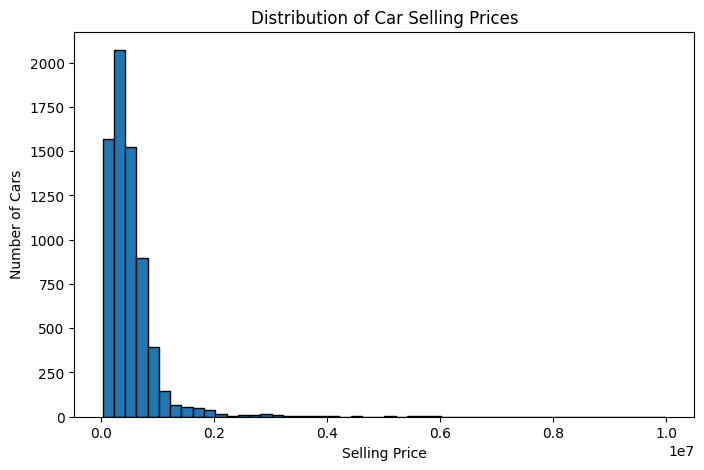

In [76]:
import matplotlib.pyplot as plt

# Statistical summary of selling prices
print(df_clean['selling_price'].describe())

# Distribution of selling prices
plt.figure(figsize=(8, 5))
plt.hist(df_clean['selling_price'], bins=50, edgecolor='black')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')
plt.title('Distribution of Car Selling Prices')
plt.show()

In [80]:
# Calculate prediction errors
residuals = y_test - y_pred_log

print("Mean Residual:", residuals.mean())
print("Maximum Error:", residuals.abs().max())
print("Minimum Error:", residuals.abs().min())

Mean Residual: 23290.613599624376
Maximum Error: 2812818.5568744475
Minimum Error: 16.089208706398495


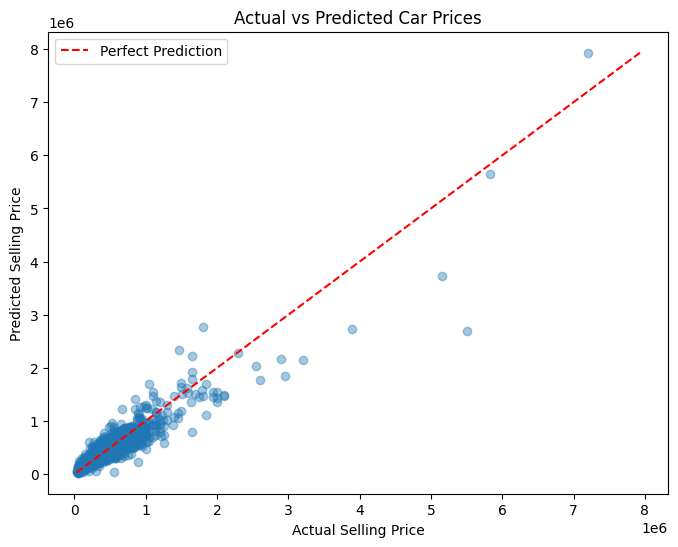

In [81]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_log, alpha=0.4)

# Ideal prediction line
min_price = min(y_test.min(), y_pred_log.min())
max_price = max(y_test.max(), y_pred_log.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")
plt.legend()
plt.show()

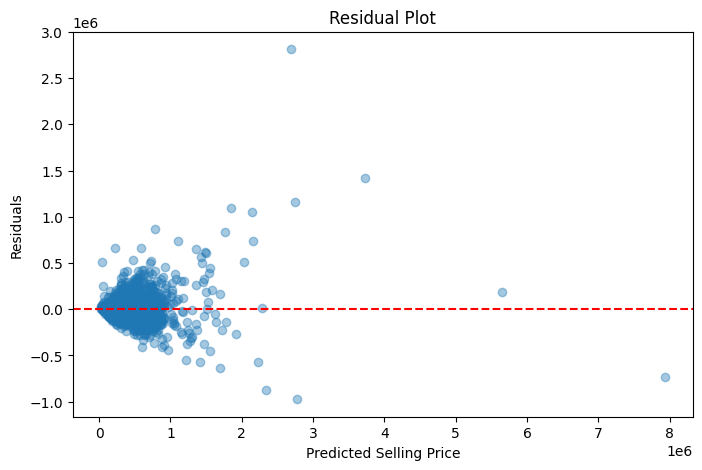

In [82]:
residuals = y_test - y_pred_log

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_log, residuals, alpha=0.4)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Selling Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [83]:
# Create a dataframe for prediction error analysis
error_analysis = X_test.copy()

error_analysis['Actual_Price'] = y_test
error_analysis['Predicted_Price'] = y_pred_log
error_analysis['Residual'] = residuals
error_analysis['Absolute_Error'] = residuals.abs()

# Display the 10 largest prediction errors
error_analysis = error_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
)
# Display prices as normal numbers without scientific notation
pd.options.display.float_format = '{:,.2f}'.format

error_analysis.head(10)


,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine (CC),max_power (bhp),seats,torque_nm,Actual_Price,Predicted_Price,Residual,Absolute_Error
7930,2019,17000,Diesel,Individual,Automatic,First Owner,18.00,"1,969.00",190.00,5.00,400.00,5500000,"2,687,181.44","2,812,818.56","2,812,818.56"
132,2019,20000,Petrol,Dealer,Automatic,First Owner,22.37,"2,487.00",214.56,5.00,202.00,5150000,"3,727,382.42","1,422,617.58","1,422,617.58"
2829,2018,17100,Diesel,Dealer,Automatic,First Owner,22.48,"1,995.00",187.74,5.00,400.00,3900000,"2,740,841.36","1,159,158.64","1,159,158.64"
1990,2018,46000,Diesel,Dealer,Manual,First Owner,15.80,"2,148.00",170.00,5.00,411.88,2950000,"1,853,770.78","1,096,229.22","1,096,229.22"
1821,2018,50000,Diesel,Individual,Manual,First Owner,14.24,"2,755.00",174.50,7.00,420.00,3200000,"2,147,187.16","1,052,812.84","1,052,812.84"
1980,2018,20000,Diesel,Dealer,Automatic,First Owner,11.36,"2,755.00",171.50,8.00,360.00,1800000,"2,773,179.87","-973,179.87","973,179.87"
4704,2017,62000,Diesel,Dealer,Automatic,First Owner,11.36,"2,755.00",171.50,7.00,360.00,1465000,"2,336,358.93","-871,358.93","871,358.93"
2137,2013,64788,Diesel,Dealer,Automatic,First Owner,NaN,"2,179.00",115.00,5.00,400.00,1650000,"785,227.31","864,772.69","864,772.69"
4375,2015,100000,Diesel,Individual,Automatic,Second Owner,15.26,"2,143.00",203.20,5.00,500.00,2600000,"1,767,096.25","832,903.75","832,903.75"
4377,2016,40000,Diesel,Individual,Automatic,Second Owner,17.90,"2,143.00",136.00,5.00,300.00,1850000,"1,111,786.02","738,213.98","738,213.98"


In [84]:
# Calculate percentage error
error_analysis['Percentage_Error'] = (
    error_analysis['Absolute_Error'] /
    error_analysis['Actual_Price']
) * 100

# Display the 10 largest prediction errors
error_analysis[
    [
        'Actual_Price',
        'Predicted_Price',
        'Residual',
        'Absolute_Error',
        'Percentage_Error'
    ]
].head(10)

,Actual_Price,Predicted_Price,Residual,Absolute_Error,Percentage_Error
7930,5500000,"2,687,181.44","2,812,818.56","2,812,818.56",51.14
132,5150000,"3,727,382.42","1,422,617.58","1,422,617.58",27.62
2829,3900000,"2,740,841.36","1,159,158.64","1,159,158.64",29.72
1990,2950000,"1,853,770.78","1,096,229.22","1,096,229.22",37.16
1821,3200000,"2,147,187.16","1,052,812.84","1,052,812.84",32.90
1980,1800000,"2,773,179.87","-973,179.87","973,179.87",54.07
4704,1465000,"2,336,358.93","-871,358.93","871,358.93",59.48
2137,1650000,"785,227.31","864,772.69","864,772.69",52.41
4375,2600000,"1,767,096.25","832,903.75","832,903.75",32.03
4377,1850000,"1,111,786.02","738,213.98","738,213.98",39.90


In [85]:
print("Prediction Error Analysis")
print("--------------------------")

print("Mean Absolute Error:",
      error_analysis['Absolute_Error'].mean())

print("Median Absolute Error:",
      error_analysis['Absolute_Error'].median())

print("Mean Percentage Error:",
      error_analysis['Percentage_Error'].mean())

print("\nTop 10 error summary:")
print(error_analysis['Absolute_Error'].head(10).describe())

Prediction Error Analysis
--------------------------
Mean Absolute Error: 106764.97582077795
Median Absolute Error: 69100.31303178321
Mean Percentage Error: 24.81158395702216

Top 10 error summary:
count          10.00
mean    1,182,406.60
std       605,675.30
min       738,213.98
25%       866,419.25
50%     1,012,996.35
75%     1,143,426.28
max     2,812,818.56
Name: Absolute_Error, dtype: float64


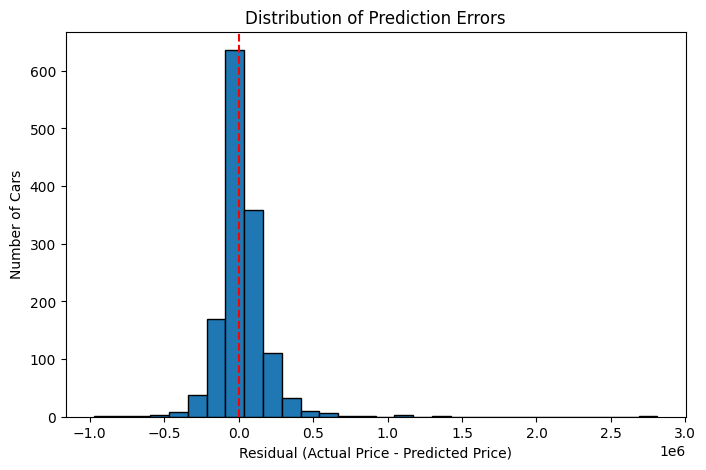

In [91]:
plt.figure(figsize=(8, 5))

plt.hist(
    error_analysis['Residual'],
    bins=30,
    edgecolor='black'
)

plt.axvline(0, color='red', linestyle='--')

plt.xlabel("Residual (Actual Price - Predicted Price)")
plt.ylabel("Number of Cars")
plt.title("Distribution of Prediction Errors")

plt.show()

In [88]:
# Store manually entered car predictions
manual_results = []

print("Manual car price prediction system is ready!")
# Enter car name for display only
car_name = input("Enter car name: ")

# Collect numerical and categorical features
car_input = {
    'year': int(input("Enter manufacturing year: ")),

    'km_driven': float(input("Enter kilometres driven: ")),

    'fuel': input(
        f"Enter fuel {list(X_train['fuel'].unique())}: "
    ),

    'seller_type': input(
        f"Enter seller type {list(X_train['seller_type'].unique())}: "
    ),

    'transmission': input(
        f"Enter transmission {list(X_train['transmission'].unique())}: "
    ),

    'owner': input(
        f"Enter owner {list(X_train['owner'].unique())}: "
    ),

    'mileage': float(input("Enter mileage: ")),

    'engine': float(input("Enter engine capacity (CC): ")),

    'max_power': float(input("Enter maximum power (bhp): ")),

    'seats': float(input("Enter number of seats: ")),

    'torque_nm': float(input("Enter torque (Nm): "))
}

# Convert input dictionary into a DataFrame
new_car = pd.DataFrame(
    [car_input],
    columns=X_train.columns
)

# Predict resale price
predicted_price = log_model.predict(new_car)[0]

print("\nCar:", car_name)
print("Predicted resale price: ₹{:,.2f}".format(predicted_price))

Manual car price prediction system is ready!

Car: maruti
Predicted resale price: ₹515,992.52


In [89]:
# Ask user for actual selling price
actual_price = float(
    input("\nEnter actual selling price (₹): ")
)

# Calculate errors
absolute_error = abs(actual_price - predicted_price)

percentage_error = (
    absolute_error / actual_price
) * 100 if actual_price != 0 else np.nan

# Store the result
manual_results.append({
    'Car_Name': car_name,
    'Actual_Price': actual_price,
    'Predicted_Price': predicted_price,
    'Absolute_Error': absolute_error,
    'Percentage_Error': percentage_error
})

print("\nPrediction Evaluation")
print("---------------------")

print("Actual Price: ₹{:,.2f}".format(actual_price))
print("Predicted Price: ₹{:,.2f}".format(predicted_price))
print("Absolute Error: ₹{:,.2f}".format(absolute_error))
print("Percentage Error: {:.2f}%".format(percentage_error))


Prediction Evaluation
---------------------
Actual Price: ₹1,490,000.00
Predicted Price: ₹515,992.52
Absolute Error: ₹974,007.48
Percentage Error: 65.37%


In [92]:
import joblib

joblib.dump(
    log_model,
    "used_car_price_model.joblib"
)

print("Trained model saved successfully!")

Trained model saved successfully!
